 *Samuel Castaño Farelo y Alvaro Colilla Martin | Grupo G-7312 | Número Pareja: 7*

# Práctica 1: Visualizacion de Datos

In [128]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os

Carga de datos inicial

In [129]:
df_uam = pd.read_csv('../data/uam-acceso-2024-25-anonimizado.csv', sep=',', low_memory=False)
df_ucm = pd.read_csv('../data/ucm-acceso-2024-25-anonimizado.csv', sep=',', low_memory=False)
df_urjc = pd.read_csv('../data/urjc-acceso-2024-25-anonimizado.csv', sep=',', low_memory=False)

df_total = pd.concat([df_uam, df_ucm, df_urjc], ignore_index=True)

In [130]:
#mapeo comodo para usar luego

map_uni = {
    'Universidad Autónoma de Madrid': 'UAM',
    'Universidad Complutense de Madrid': 'UCM',
    'Universidad Rey Juan Carlos': 'URJC'
}

In [131]:
df_total['universidad_corta'] = df_total['des_universidad'].map(map_uni).fillna(df_total['des_universidad'])
print(df_total.head())

                                          IMPORTANTE  cod_universidad  \
0  LOS DATOS DE ESTA FILA NO CORRESPONDEN A UN SÓ...               23   
1  LOS DATOS DE ESTA FILA NO CORRESPONDEN A UN SÓ...               23   
2  LOS DATOS DE ESTA FILA NO CORRESPONDEN A UN SÓ...               23   
3  LOS DATOS DE ESTA FILA NO CORRESPONDEN A UN SÓ...               23   
4  LOS DATOS DE ESTA FILA NO CORRESPONDEN A UN SÓ...               23   

                  des_universidad curso_academico  cod_campus   des_campus  \
0  Universidad Autónoma de Madrid         2024-25        2301  Cantoblanco   
1  Universidad Autónoma de Madrid         2024-25        2301  Cantoblanco   
2  Universidad Autónoma de Madrid         2024-25        2301  Cantoblanco   
3  Universidad Autónoma de Madrid         2024-25        2301  Cantoblanco   
4  Universidad Autónoma de Madrid         2024-25        2301  Cantoblanco   

   cod_centro           des_centro  cod_naturaleza_centro  \
0  28027084.0  Facultad de Dere

### Apartado 1.1: Forma de admisión

Veamos los porcentajes de las formas de admisión

In [132]:
porcentajes = df_total['des_forma_admision'].value_counts(normalize=True) * 100
print(porcentajes)

des_forma_admision
Pruebas de Acceso a la Universidad (EVAU, PAU y Pruebas de Acceso anteriores)                                                                                                                                                                                82.613378
Mediante posesión de los títulos de Técnica/o Superior correspondientes a las enseñanzas de Formación Profesional y Enseñanzas Artísticas o de Técnica/o Deportiva/o Superior correspondientes a las enseñanzas Deportivas o títulos equivalentes             9.539907
Estudiantes procedentes de sistemas miembros de la Unión Europea o de otros Estados con los que España haya suscrito Acuerdos Internacionales a este respecto que cumplan los requisitos exigidos en su respectivo país para el acceso a la universidad.      4.023573
Por poseer otro título universitario o título equivalente                                                                                                                                       

Ya nos damos cuenta que la forma de admision por Evau es masiva comparada al resto de formas, lo cual intuimos que nos dara un gŕafico desbalanceado y poco legible

Probamos con un gráfico pie 

/tmp/ipykernel_4854/3332968478.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


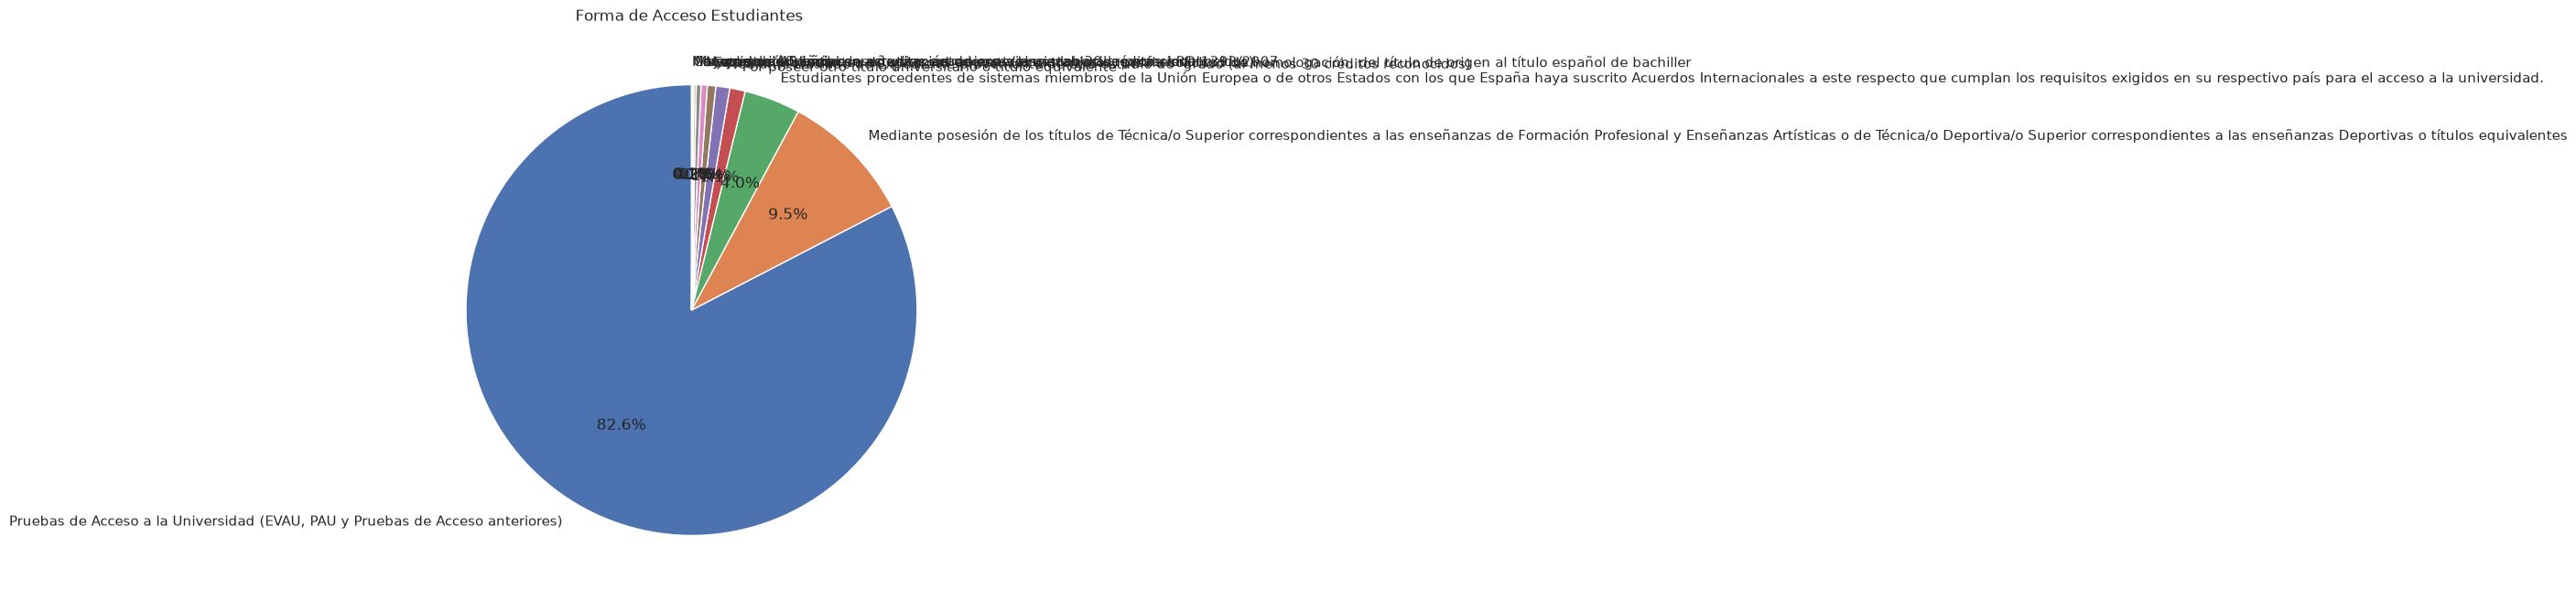

In [133]:
plt.figure(figsize=(10,8))
plt.pie(
    porcentajes.values,
    labels = porcentajes.index,
    autopct = '%.1f%%',
    startangle = 90,

)

plt.title("Forma de Acceso Estudiantes ")
plt.tight_layout()
plt.show()

Esta gráfica no nos sirve. La Admisión por Evau es tan masiva que no nos deja ver las demás opciones con claridad. Además tenemos otro problema: Los nombres son muy largos para ser leidos con facilidad

In [134]:
mapeo_vias = {

    'Pruebas de Acceso a la Universidad (EVAU, PAU y Pruebas de Acceso anteriores)': ('EvAU (Bachillerato)'),

    (
        'Estudiantes procedentes de sistemas miembros de la Unión Europea o de'
        ' otros Estados con los que España haya suscrito Acuerdos'
        ' Internacionales a este respecto que cumplan los requisitos exigidos'
        ' en su respectivo país para el acceso a la universidad.'
    ): 'Sistemas UE / Acuerdos',


    (
        'Mediante posesión de los títulos de Técnica/o Superior'
        ' correspondientes a las enseñanzas de Formación Profesional y'
        ' Enseñanzas Artísticas o de Técnica/o Deportiva/o Superior'
        ' correspondientes a las enseñanzas Deportivas o títulos equivalentes'


    ): 'FP Superior o Artísticas',
    'Mayores de 25 años': '> 25 años',
    'Mayores de 40 años con acreditación de experiencia laboral o profesional': (
        '> 40 años (Exp. Laboral)'


    ),
    'Mayores de 45 años.': '> 45 años',
    'Mayores de 45 años': '> 45 años',


    (
        'Estudios procedentes de sistemas educativos extranjeros, previa'
        ' solicitud de homologación, del título de origen al título español de'
        ' bachiller'


    ): 'Homologación Bachiller Extr.',
    'Por poseer otro título universitario o título equivalente': (
        'Titulados Universitarios'


    ),
    (
        'Convalidación parcial de estudios extranjeros (al menos 30 créditos'
        ' reconocidos)'
    ): 'Conval. Extranjera (≥30 ECTS)',


    (
        'Mediante traslado de Expediente proveniente de otro estudio de grado'
        ' (al menos 30 créditos reconocidos)'
    ): 'Traslado de Grado (≥30 ECTS)',


    (
        'Incorporación desde enseñanzas anteriores a las establecidas por el'
        ' RD 1393/2007'
    ): 'Planes anteriores (RD 1393)',

    
    (
        'Acceso sin prueba de acceso para estudiantes de Bachillerato anterior'
        ' al Bachillerato LOMCE'
    ): 'Bachillerato pre-LOMCE',
}

# posibles espacios
porcentajes.index = (porcentajes.index.astype(str).str.strip().str.replace(r'\s+', ' ', regex=True))

porcentajes_cortos = porcentajes.rename(index=mapeo_vias)
porcentajes_ordenados = porcentajes_cortos.sort_values(ascending=False)

porcentajes_cortos = porcentajes.rename(index=mapeo_vias)

In [135]:
# Ordenamos los procentajes de Mayor a menor
porcentajes_ordenados = porcentajes_cortos.sort_values(ascending=False)

Ahora realizamos un gráfico de barras 

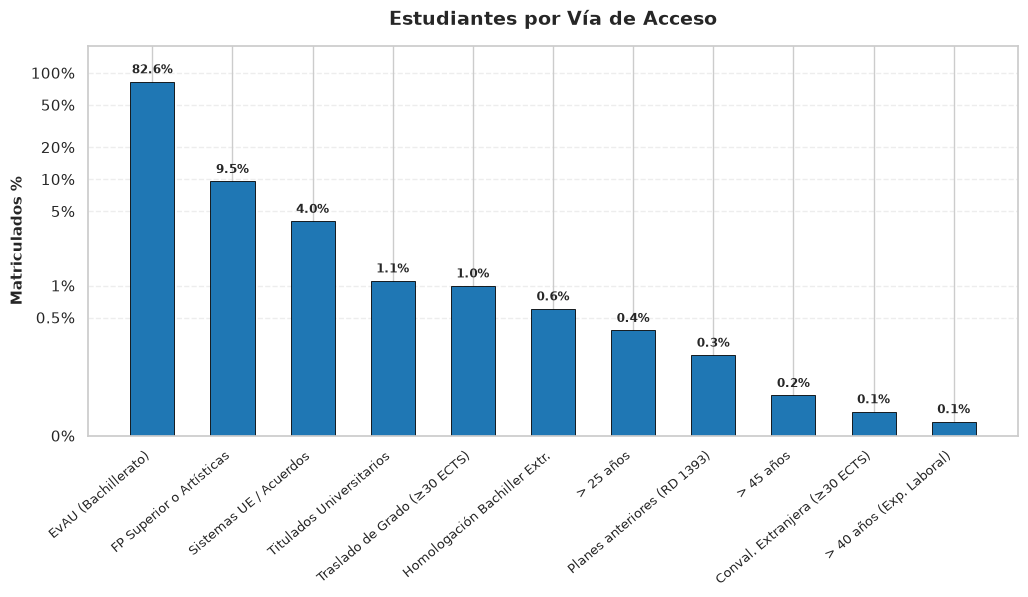

In [136]:
fig_1_1, ax = plt.subplots(figsize=(12, 6.5))

barras = ax.bar(
    porcentajes_ordenados.index,
    porcentajes_ordenados.values,
    color='#1f77b4',
    edgecolor='black',
    linewidth=0.6,
    width=0.55
)

ax.set_yscale('symlog', linthresh=0.5) # Escala hibrida para poder representar los porcentajes pequeños sin problema
ax.set_ylim(0, 180) # Para que no se salga la gráfica


#marcas
ax.set_yticks([0, 0.5, 1, 5, 10, 20, 50, 100])
ax.set_yticklabels(['0%', '0.5%', '1%', '5%', '10%', '20%', '50%', '100%'])

ax.set_title('Estudiantes por Vía de Acceso', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Matriculados %', fontsize=11, fontweight='bold')

ax.set_xticks(range(len(porcentajes_ordenados.index)))
ax.set_xticklabels(porcentajes_ordenados.index, rotation=40, ha='right', fontsize=9.5)
ax.grid(axis='y', linestyle='--', alpha=0.35)


ax.bar_label(barras, fmt='%.1f%%', padding=4, fontsize=8.5, fontweight='bold')

plt.subplots_adjust(top=0.90, bottom=0.30)
plt.show()

#### Preguntas: 

- ¿Qué vía de acceso agrupa a la mayor proporción de matriculados?

La vía principal es la de "Pruebas de Acceso a la Universidad (EvAU / Bachillerato)", agrupa al 82.6% de los estudiantes matriculados en el conjunto de las tres universidades.


- Si excluyes esa vía principal, ¿qué otro cupo destaca sobre los demás? ¿Tuviste que tomar alguna
decisión de diseño en tu gráfico para poder visualizar y comparar correctamente estos cupos minori
tarios?

Si excluimos la evau, el cupo que sobresale es la Formación Profesional Superior o Enseñanzas Artísticas (FP Superior), con un 9.5% de los matriculados. 

**Decisiones de diseño adoptadas**: 

Se descartó el gráfico pie porque la enorme diferencia entre el 82.6% y los inferiores al 1% generaba porciones invisibles y textos solapados ilegibles. En su lugar se optó por un gráfico de barras verticales ordenado de mayor a menor. Tambien hizimos un mapeo de etiquetas: Las descripciones originales del dataset eran excesivamente largas, por lo que se mapearon a nombres concisos.

### Apartado 1.2: Tasa Acceso y Exigencias

In [137]:
# cargamos solo las ramas y el codigo

df_ramas = pd.read_excel('../data/Titulaciones_rama-campo-2024.xlsx', sheet_name='Titulación_Rama', skiprows=5).iloc[:, [4, 8]]
df_ramas.columns = ['cod_titulacion', 'rama_conocimiento']

# a str
df_total['cod_titulacion'] = (df_total['cod_titulacion'].astype(str).str.split('.').str[0])
df_ramas['cod_titulacion'] = (df_ramas['cod_titulacion'].astype(str).str.split('.').str[0])
df_ramas = df_ramas.drop_duplicates('cod_titulacion')

# Convierte a número
df_total['nota_admision'] = pd.to_numeric(df_total['nota_admision'].astype(str).str.replace(',', '.'),errors='coerce',)

In [138]:
# mergeo
df_total = df_total.merge(df_ramas, on='cod_titulacion', how='left')

In [139]:
tasa = df_total['rama_conocimiento'].value_counts(normalize=True).mul(100)

solo_nota = df_total[df_total['nota_admision'] > 0]
media_nota = solo_nota.groupby('rama_conocimiento')['nota_admision'].mean()

# unimos y ordenamos de mayor a menor tasa
resumen = (pd.DataFrame({'tasa': tasa, 'nota': media_nota}).sort_values(by='tasa', ascending=False).dropna())


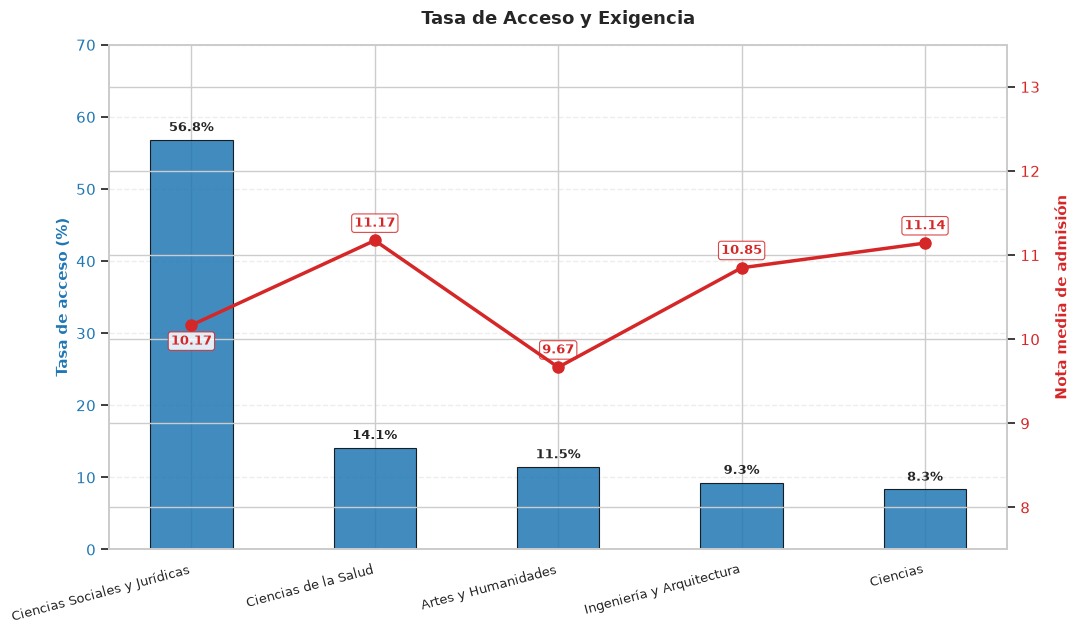

In [140]:
fig_1_2, ax1 = plt.subplots(figsize=(11, 6.5))

barras = ax1.bar(
    resumen.index,
    resumen['tasa'],
    color='#1f77b4',
    width=0.45,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.8,
    zorder=2
)

ax1.set_ylabel('Tasa de acceso (%)', color='#1f77b4', fontsize=11, fontweight='bold')
ax1.set_ylim(0, 70)
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.bar_label(barras, fmt='%.1f%%', padding=4, fontsize=9.5, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.35, zorder=1)

# Inclinación sutil para que los textos largos no se toquen
ax1.set_xticks(range(len(resumen.index)))
ax1.set_xticklabels(resumen.index, rotation=15, ha='right', fontsize=9.5)

ax2 = ax1.twinx()
ax2.plot(
    resumen.index,
    resumen['nota'],
    color='#d62728',
    marker='o',
    linewidth=2.5,
    markersize=8,
    zorder=4
)
ax2.set_ylabel(
    'Nota media de admisión',
    color='#d62728',
    fontsize=11,
    fontweight='bold',
    labelpad=10
)
ax2.set_ylim(7.5, 13.5)
ax2.tick_params(axis='y', labelcolor='#d62728')

for i, val in enumerate(resumen['nota']):
    offset_y = -14 if i == 0 else 10
    
    ax2.annotate(
        f'{val:.2f}',
        (i, val),
        textcoords='offset points',
        xytext=(0, offset_y),
        ha='center',
        color='#d62728',
        fontweight='bold',
        fontsize=9.5,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#d62728', alpha=0.85, lw=0.8)
    )

plt.title(
    'Tasa de Acceso y Exigencia',
    fontsize=13,
    fontweight='bold',
    pad=15,
)

fig_1_2.tight_layout()
plt.show()

#### Pregunta:

* Busca un informe o noticia de un medio que hable sobre las carreras más solicitadas del curso académico que estás analizando. Compáralo con los datos que muestras y explica, brevemente, cómo tu propuesta de visualización mejora o completa la fuente que has elegido.

**Fuente seleccionada:**
- https://www.rtve.es/noticias/20250517/100-carreras-mas-demandadas-universidad-publica-se-estudian/16559324.shtml
- Informe de RTVE Noticias (*«Las 100 carreras más demandadas de la universidad pública y dónde se estudian»*, curso 2024-2025).

**Comparativa y mejoras de nuestra propuesta:**  
La noticia se enfoca en el rankin de notas de corte extremas (dobles grados de Matemáticas o Física y Medicina ...), equiparando erróneamente la demanda con la nota de corte más alta de grados con muy pocas plazas.

Nuestra gráfica mejora y complementa la fuente porque:
1. **Refleja el volumen real de matrícula:** Muestra que los verdaderos estudiantes se concentra en ciencias sociales y jurídicas (56.8%), una rama con notas medias moderadas (10.17) que no se menciona en los titulares de prensa.
2. **Integra volumen y exigencia en una sola vista:** Al cruzar la tasa de acceso con la nota media , nos permite entender la relación entre plazas ocupadas y nivel de exigencia por rama, desmitificando narrativas de prensa que son solo casos atípicos.

### 2.1: Estudiantes por Vía de Acceso y Universidad (Subplots)

In [141]:
vias_mapeadas = df_total['des_forma_admision'].str.strip().str.replace(r'\s+', ' ', regex=True).map(mapeo_vias)
tabla_vias_uni = pd.crosstab(vias_mapeadas, df_total['universidad_corta'], normalize='columns') * 100

tabla_vias_uni = tabla_vias_uni.reindex(porcentajes_ordenados.index).fillna(0)

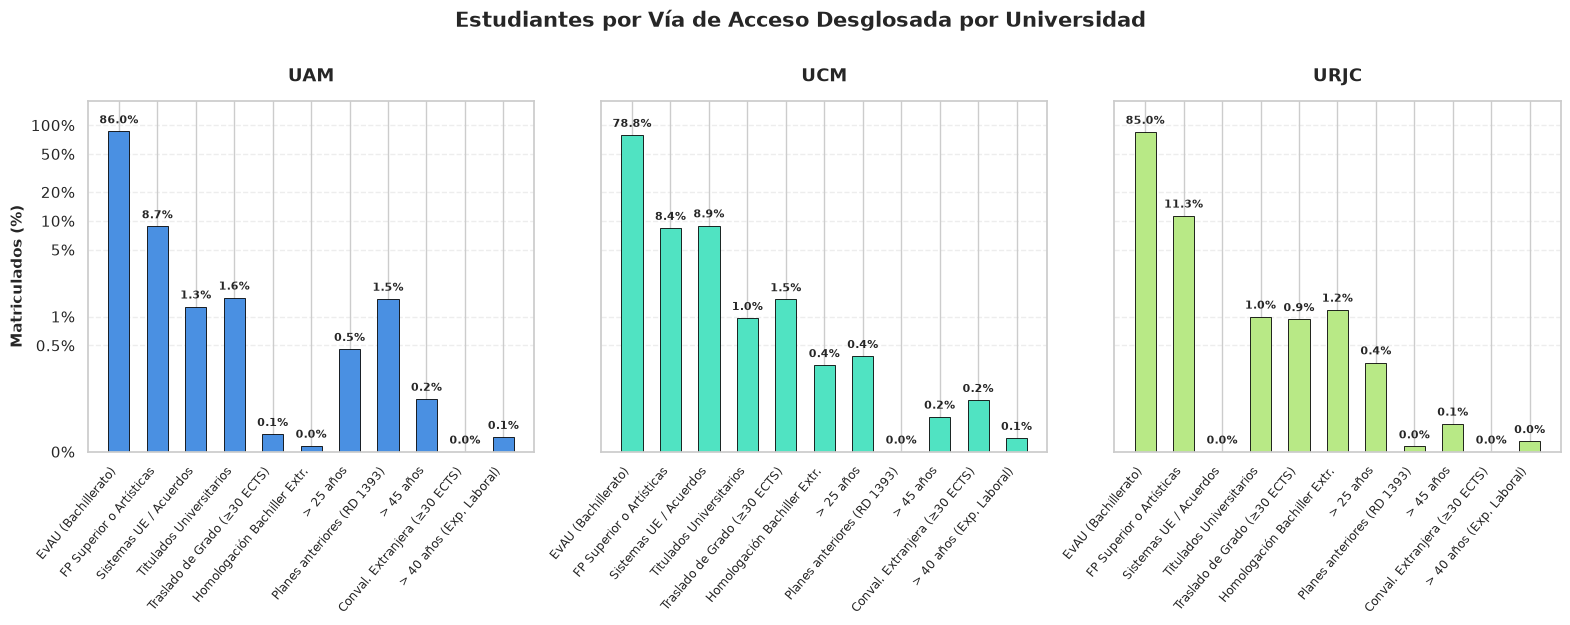

In [142]:
fig_2_1, axes = plt.subplots(1, 3, figsize=(19, 6.5), sharey=True)
universidades = ['UAM', 'UCM', 'URJC']
colores = ['#4a90e2', '#50e3c2', '#b8e986']

for i, (uni, ax) in enumerate(zip(universidades, axes)):
    valores = tabla_vias_uni[uni]
    barras = ax.bar(
        valores.index, 
        valores.values, 
        color=colores[i], 
        edgecolor='black', 
        linewidth=0.6,
        width=0.55
    )
    
    
    ax.set_yscale('symlog', linthresh=0.5) # Escala hibrida logritmica como antes
    ax.set_ylim(0, 180)

    ax.set_yticks([0, 0.5, 1, 5, 10, 20, 50, 100])
    ax.set_yticklabels(['0%', '0.5%', '1%', '5%', '10%', '20%', '50%', '100%'])
    
    ax.set_title(uni, fontsize=13, fontweight='bold', pad=14)
    ax.set_xticks(range(len(valores.index)))
    ax.set_xticklabels(valores.index, rotation=50, ha='right', fontsize=8.5)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    
    ax.bar_label(barras, fmt='%.1f%%', padding=4, fontsize=7.8, fontweight='bold')
    
    if i == 0:
        ax.set_ylabel('Matriculados (%)', fontsize=11, fontweight='bold')

plt.suptitle('Estudiantes por Vía de Acceso Desglosada por Universidad', fontsize=15, fontweight='bold', y=0.98)
plt.subplots_adjust(top=0.84, bottom=0.30, wspace=0.15)
plt.show()

**Universidad con mayor porcentaje por vía**

In [143]:
for via in tabla_vias_uni.index:
    uni_max = tabla_vias_uni.loc[via].idxmax()
    pct_max = tabla_vias_uni.loc[via, uni_max]
    print(f"{via}: {uni_max} ({pct_max:.2f}%)")

EvAU (Bachillerato): UAM (85.97%)
FP Superior o Artísticas: URJC (11.31%)
Sistemas UE / Acuerdos: UCM (8.94%)
Titulados Universitarios: UAM (1.57%)
Traslado de Grado (≥30 ECTS): UCM (1.51%)
Homologación Bachiller Extr.: URJC (1.18%)
> 25 años: UAM (0.48%)
Planes anteriores (RD 1393): UAM (1.53%)
> 45 años: UAM (0.25%)
Conval. Extranjera (≥30 ECTS): UCM (0.24%)
> 40 años (Exp. Laboral): UAM (0.07%)


### Justificación del diseño
Optamos por una disposición horizontal en una sola fila para facilitar la comparación paralela inmediata entre las tres universidades. Además, se asignó un color diferenciado a cada universidad para reforzar la distinción entre subplots.

---

#### Pregunta:

* Por cada una de las vías de acceso, ¿cuál es la universidad que tiene el mayor porcentaje de acceso?

A partir de los porcentajes normalizados dentro de cada universidad:

* **EvAU:** **UAM** (85.97%)
* **FP Superior o Artísticas:** **URJC** (11.31%)
* **Sistemas UE:** **UCM** (8.94%)
* **Titulados Universitarios:** **UAM** (1.57%)
* **Traslado de Grado:** **UCM** (1.51%)
* **Bachiller Extranjero:** **URJC** (1.18%)
* **Mayores de 25 años:** **UAM** (0.48%)
* **Planes anteriores:** **UAM** (1.53%)
* **Mayores de 45 años:** **UAM** (0.25%)
* **Convalidación Parcial Extranjera:** **UCM** (0.24%)
* **Mayores de 40 años:** **UAM** (0.07%)

### 2.2 Nota media por Universidad

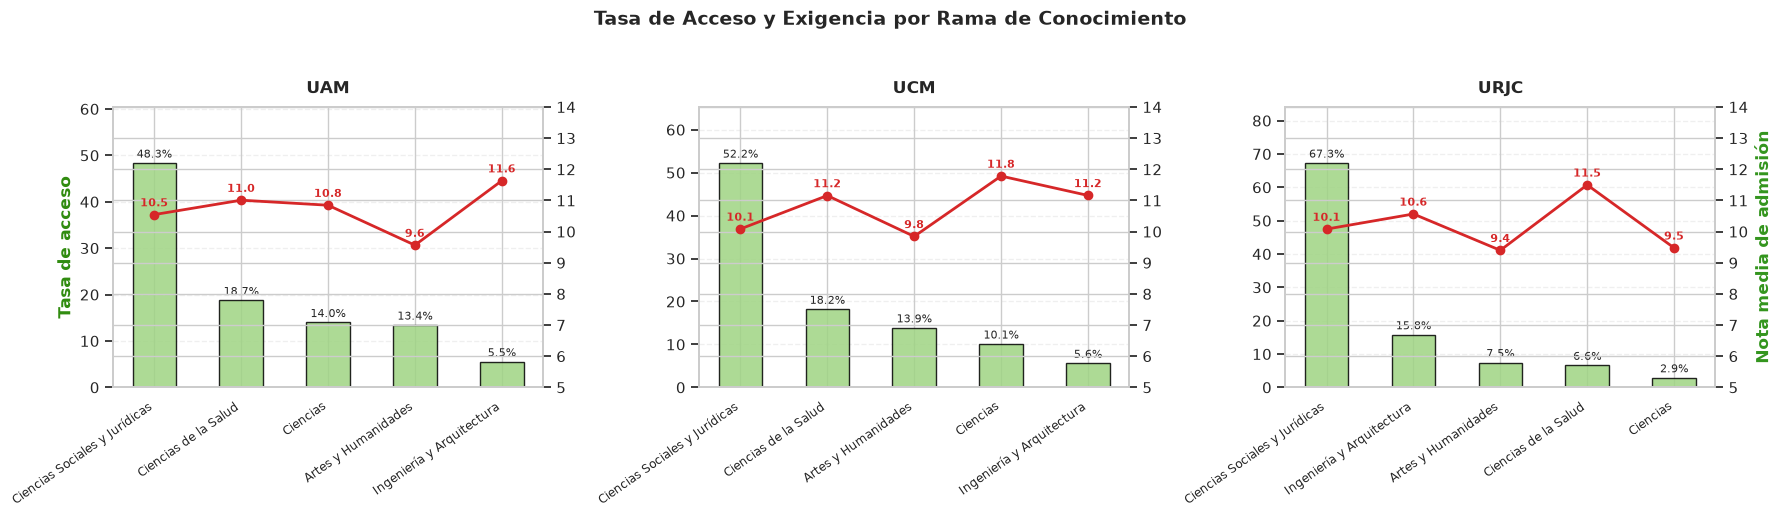

In [144]:
universidades = {'UAM': df_uam, 'UCM': df_ucm, 'URJC': df_urjc}
fig_2_2, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (nombre, df_uni) in enumerate(universidades.items()):
  ax1 = axes[i]

  if 'rama_conocimiento' not in df_uni.columns:
    df_uni['cod_titulacion'] = (df_uni['cod_titulacion'].astype(str).str.split('.').str[0])
    df_uni = df_uni.merge(df_ramas, on='cod_titulacion', how='left')

  df_uni['nota_admision'] = pd.to_numeric(df_uni['nota_admision'].astype(str).str.replace(',', '.'), errors='coerce')

  tasa = df_uni['rama_conocimiento'].value_counts(normalize=True).mul(100)
  solo_nota = df_uni[df_uni['nota_admision'] > 0]
  media_nota = solo_nota.groupby('rama_conocimiento')['nota_admision'].mean()

  resumen = (pd.DataFrame({'tasa': tasa, 'nota': media_nota}).sort_values(by='tasa', ascending=False).dropna())
  x = range(len(resumen))


  barras = ax1.bar(
      x,
      resumen['tasa'],
      color='#9fd483',
      width=0.5,
      alpha=0.85,
      edgecolor='black',
  )
  
  ax1.set_title(nombre, fontsize=12, fontweight='bold', pad=10)
  ax1.set_xticks(x)
  ax1.set_xticklabels(resumen.index, rotation=35, ha='right', fontsize=8.5)
  ax1.set_ylim(0, max(resumen['tasa']) * 1.25)
  ax1.bar_label(barras, fmt='%.1f%%', padding=2, fontsize=8)
  ax1.grid(axis='y', linestyle='--', alpha=0.3)

  if i == 0:
    ax1.set_ylabel(
        'Tasa de acceso',
        color='#318C10', 
        fontweight='bold')

  ax2 = ax1.twinx()
  ax2.plot(
      x, resumen['nota'],
      color='#d62728',
      marker='o',
      linewidth=2,
      markersize=6
  )
  ax2.set_ylim(5, 14)

  if i == 2:
    ax2.set_ylabel(
        'Nota media de admisión',
        color='#34951E',
        fontweight='bold',
    )

  for j, val in enumerate(resumen['nota']):
    ax2.annotate(
        f'{val:.1f}',
        (j, val),
        textcoords='offset points',
        xytext=(0, 6),
        ha='center',
        fontsize=8,
        color='#d62728',
        fontweight='bold',
    )

plt.suptitle(
    'Tasa de Acceso y Exigencia por Rama de Conocimiento',
    fontsize=14,
    fontweight='bold',
    y=1.03,
)
plt.tight_layout()
plt.show()

#### Preguntas:


 **¿Qué rama es la que tiene mayor tasa de acceso?**
  * **UAM:** Ciencias Sociales y Jurídicas (48.3%)
  * **UCM:** Ciencias Sociales y Jurídicas (52.2%)
  * **URJC:** Ciencias Sociales y Jurídicas (67.3%)
  
  **¿Qué rama es la más exigente por nota de acceso?**
  * **UAM:** Ingeniería y Arquitectura (nota media: 11.6)
  * **UCM:** Ciencias (nota media: 11.8)
  *  **URJC:** Ciencias de la Salud (nota media: 11.5)


**¿Cuál es la rama de conocimiento y en qué universidad es la más exigente por nota de acceso?**  
    La combinación más exigente de todo el sistema es Ciencias en la UCM, con una nota media de admisión de 11.8.

### Apartado 2.3: Exportación de gráficas

In [145]:
carpeta_pdf = 'graficas_pdf'
os.makedirs(carpeta_pdf, exist_ok=True)

figuras_a_exportar = {
    'apartado_1_1.pdf': fig_1_1,
    'apartado_1_2.pdf': fig_1_2,
    'apartado_2_1.pdf': fig_2_1,
    'apartado_2_2.pdf': fig_2_2,
}

for nombre_archivo, figura in figuras_a_exportar.items():
    ruta = os.path.join(carpeta_pdf, nombre_archivo)
    figura.savefig(ruta, format='pdf', bbox_inches='tight', dpi=300)
    print(f"exportado: {ruta}")

exportado: graficas_pdf/apartado_1_1.pdf
exportado: graficas_pdf/apartado_1_2.pdf
exportado: graficas_pdf/apartado_2_1.pdf
exportado: graficas_pdf/apartado_2_2.pdf


### Apartado 3.1: Distribución de las notas de acceso por universidad y rama de conocimiento

In [146]:
df_notas_validas = df_total[(df_total['nota_admision'] > 0) & (df_total['rama_conocimiento'].notna())].copy()

def dispersion(series):
    q75 = series.quantile(0.75)
    q25 = series.quantile(0.25)
    return pd.Series({
        'IQR (Q75 - Q25)': q75 - q25,
        'Desv. Estándar': series.std(),
        'Media': series.mean(),
        'Mediana': series.median()
    })

tabla_dispersion = df_notas_validas.groupby(['universidad_corta', 'rama_conocimiento'])['nota_admision'].apply(dispersion).unstack()

print("Ramas y universidaes notas comprimidas")
display(tabla_dispersion.sort_values(by='IQR (Q75 - Q25)').head(5))

Ramas y universidaes notas comprimidas


IQR (Q75 - Q25)  \
universidad_corta rama_conocimiento                                
URJC              Ingeniería y Arquitectura               1.7870   
UAM               Ingeniería y Arquitectura               1.9120   
                  Ciencias de la Salud                    1.9435   
URJC              Ciencias de la Salud                    2.1190   
UAM               Ciencias Sociales y Jurídicas           2.1980   

                                                 Desv. Estándar      Media  \
universidad_corta rama_conocimiento                                          
URJC              Ingeniería y Arquitectura            1.474505  10.565812   
UAM               Ingeniería y Arquitectura            1.325853  11.633504   
                  Ciencias de la Salud                 2.043703  11.008342   
URJC              Ciencias de la Salud                 1.579326  11.499834   
UAM               Ciencias Sociales y Jurídicas        1.783865  10.545945   

                                                 Mediana  
universidad_corta rama_conocimiento                       
URJC              Ingeniería y Arquitectura       10.714  
UAM               Ingeniería y Arquitectura       11.525  
                  Ciencias de la Salud            11.336  
URJC              Ciencias de la Salud            11.740  
UAM               Ciencias Sociales y Jurídicas   10.961

/tmp/ipykernel_4854/1248397026.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=10)


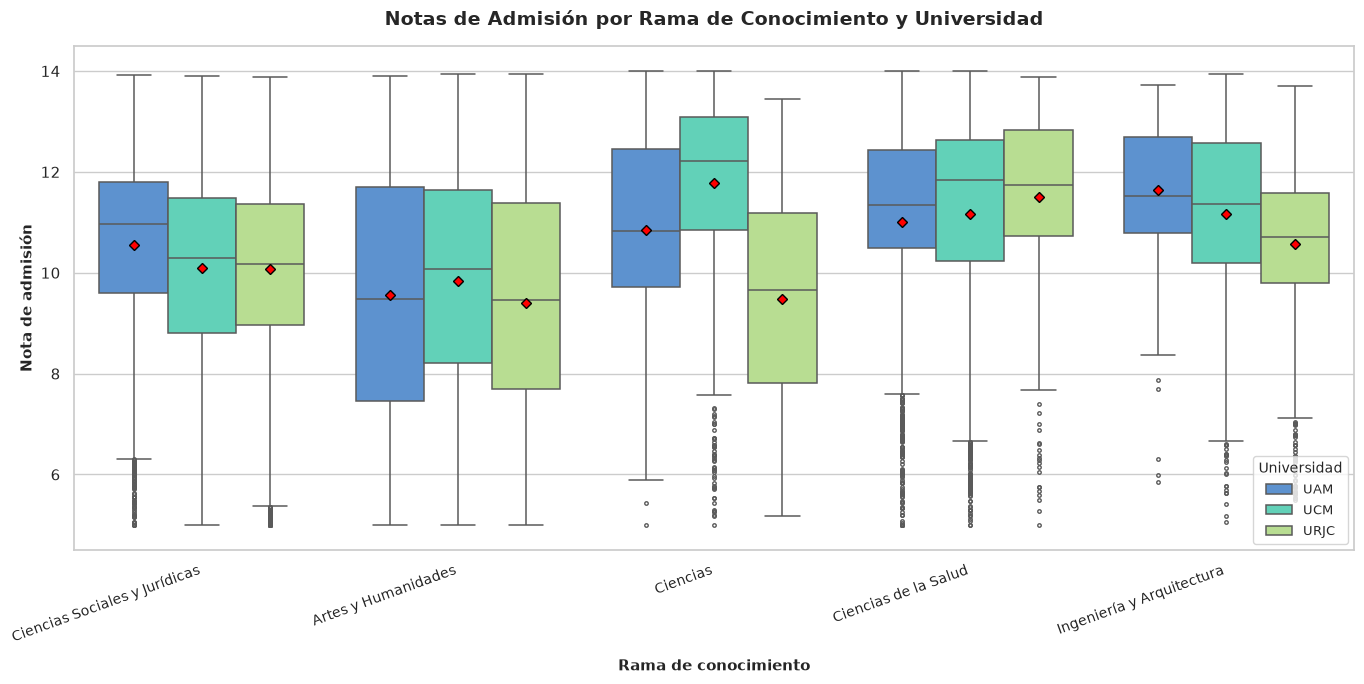

In [147]:
sns.set_theme(style="whitegrid")
fig_3_1, ax = plt.subplots(figsize=(14, 7))

paleta_unis = {'UAM': '#4a90e2', 'UCM': '#50e3c2', 'URJC': '#b8e986'}

sns.boxplot(
    data=df_notas_validas,
    x='rama_conocimiento',
    y='nota_admision',
    hue='universidad_corta',
    palette=paleta_unis,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 5
    },
    linewidth=1.1,
    fliersize=2.5,
    ax=ax
)

ax.set_ylim(4.5, 14.5)
ax.set_title('Notas de Admisión por Rama de Conocimiento y Universidad', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Rama de conocimiento', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Nota de admisión', fontsize=11, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=10)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles=handles, 
    labels=labels, 
    title='Universidad', 
    title_fontsize='10', 
    fontsize=9.5, 
    loc='lower right'
)

fig_3_1.tight_layout()
plt.show()

#### Preguntas:

* **¿Qué rama de conocimiento y en qué universidad la distribución de las notas está más comprimida?**  
  La distribución más comprimida se encuentra en Ciencias de la Salud. Las notas se concentran por encima del 10.5 - 11.

* **¿A qué se puede deber este comportamiento con respecto al de otras ramas de conocimiento?**  
  Se debe a la alta demanda y al número reducido de plazas ofertadas en titulaciones sanitarias.Hay una nota de corte de acceso muy elevada y homogénea en prácticamente todas las carreras de la rama, todos los alumnos ingresan con calificaciones muy altas y similares.

### Apartado 3.2: Análisis de notas medias de acceso por universidad y titulación (Seaborn)

In [148]:
col_tit = None

for c in ['des_titulacion', 'des_estudio', 'nom_titulacion', 'nom_estudio']:
    if c in df_total.columns:
        col_tit = c
        break
if col_tit is None:
    col_tit = [c for c in df_total.columns if 'titulacion' in c.lower() or 'estudio' in c.lower()][0]

df_validas = df_total[(df_total['nota_admision'] > 0) & (df_total[col_tit].notna()) & (df_total['rama_conocimiento'].notna())].copy()

df_tit_uni = df_validas.groupby([col_tit, 'universidad_corta', 'rama_conocimiento'])['nota_admision'].mean().reset_index()
df_tit_uni.rename(columns={col_tit: 'titulacion'}, inplace=True)

def acortar_nombre(n):
    t = str(n).strip()
    t = t.replace('Graduado o Graduada en Medicina por la Universidad Autónoma de Madrid', 'Medicina')
    t = t.replace('Graduado o Graduada en ', '').replace('Grado en ', '').replace('GRADO EN ', '')
    t = t.replace('DOBLE GRADO EN ', 'Doble Grado ').replace('DOBLE GRADO ', 'Doble Grado ')
    t = t.replace('(2019)', '').strip()
    return t[:32] + ('...' if len(t) > 32 else '')

df_tit_uni['nombre_limpio'] = df_tit_uni['titulacion'].apply(acortar_nombre)

top_absoluta = df_tit_uni.sort_values(by='nota_admision', ascending=False).iloc[0]

print("-"*65)
print(f"Titulación mas exigente: {top_absoluta['titulacion']}")
print(f"Universidad: {top_absoluta['universidad_corta']}")
print(f"Medja: {top_absoluta['nota_admision']:.2f} / 14")

-----------------------------------------------------------------
Titulación mas exigente: DOBLE GRADO MATEMÁTICAS - FÍSICA (2019)
Universidad: UCM
Medja: 13.72 / 14


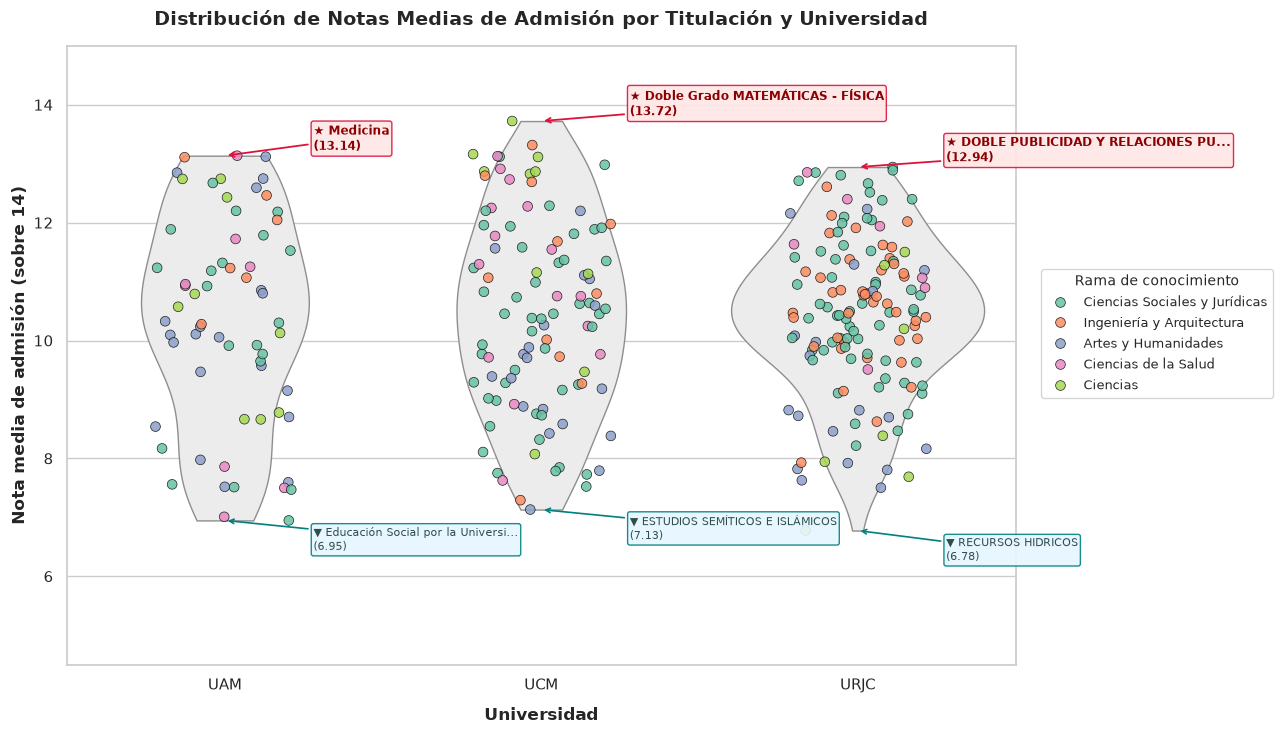

In [149]:
sns.set_theme(style="whitegrid")
fig_3_2, ax = plt.subplots(figsize=(13, 7.5))

orden_uni = ['UAM', 'UCM', 'URJC']

sns.violinplot(
    data=df_tit_uni,
    x='universidad_corta',
    y='nota_admision',
    order=orden_uni,
    color='#ececec',
    inner=None,
    cut=0,
    linewidth=1,
    ax=ax
)

sns.stripplot(
    data=df_tit_uni,
    x='universidad_corta',
    y='nota_admision',
    hue='rama_conocimiento',
    order=orden_uni,
    jitter=0.22,
    size=7,
    alpha=0.85,
    palette='Set2',
    edgecolor='black',
    linewidth=0.5,
    ax=ax
)

ax.set_ylim(4.5, 15.0)
ax.set_title('Distribución de Notas Medias de Admisión por Titulación y Universidad', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Universidad', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Nota media de admisión (sobre 14)', fontsize=12, fontweight='bold')

for idx, uni in enumerate(orden_uni):
    sub = df_tit_uni[df_tit_uni['universidad_corta'] == uni].sort_values(by='nota_admision', ascending=False)
    
    top_uni = sub.iloc[0]
    ax.annotate(
        f"★ {top_uni['nombre_limpio']}\n({top_uni['nota_admision']:.2f})",
        xy=(idx, top_uni['nota_admision']),
        xytext=(idx + 0.28, top_uni['nota_admision'] + 0.1),
        arrowprops=dict(arrowstyle="->", color="crimson", lw=1.3),
        fontsize=8.5, fontweight='bold', color='darkred',
        bbox=dict(boxstyle="round,pad=0.2", facecolor='#ffe6e6', edgecolor='crimson', alpha=0.9)
    )
    
    bot_uni = sub.iloc[-1]
    
    ax.annotate(
        f"▼ {bot_uni['nombre_limpio']}\n({bot_uni['nota_admision']:.2f})",
        xy=(idx, bot_uni['nota_admision']),
        xytext=(idx + 0.28, bot_uni['nota_admision'] - 0.5),
        arrowprops=dict(arrowstyle="->", color="teal", lw=1.2),
        fontsize=8, color='darkslategray',
        bbox=dict(boxstyle="round,pad=0.2", facecolor='#e6f7ff', edgecolor='teal', alpha=0.9)
    )

ax.legend(
    title='Rama de conocimiento', 
    bbox_to_anchor=(1.02, 0.65),
    loc='upper left', 
    fontsize=9.5, 
    title_fontsize=10
)
plt.tight_layout()
plt.show()

### Justificación del diseño
Se utilizo un mapa de calor porque permite representar una matriz bidimensional compacta y visualmente. Dado que el conjunto de datos cuenta con cientos de titulaciones, incluir la totalidad de carreras saturaría el eje Y impidiendo leer los nombres. Por tanto nuetrsa decision fue filtrar los dos extremos.
Además, las tres universidades estan en columnas paralelas lo que facilita ver al instante la diferencia de exigencia de una misma titulación entre universidae.

### Preguntas

**Según los datos representados, ¿cuál es la titulación más exigente para poder acceder?**
La titulación con mayor exigencia media de acceso es la que encabeza el bloque superior, doble grado de Matemáticas y Física, doble grado en Publicidad y Relaciones y el grado en Medicina. Con notas medias 12.94 - 13.72.

**¿Y en qué universidad tiene la titulación más exigente para acceder?**
La titulación más exigente del sistema se localiza en la UCM.

In [150]:
# exportacion de las gráficas que qeudan
figuras_parte3 = {
    'apartado_3_1.pdf': fig_3_1,
    'apartado_3_2.pdf': fig_3_2,
}

for nombre_archivo, figura in figuras_parte3.items():
    ruta = os.path.join(carpeta_pdf, nombre_archivo)
    figura.savefig(ruta, format='pdf', bbox_inches='tight', dpi=300)
    print(f"Exportado correctamente: {ruta}")

Exportado correctamente: graficas_pdf/apartado_3_1.pdf
Exportado correctamente: graficas_pdf/apartado_3_2.pdf
